# Plot the time series of each simulation 

In [1]:
import numpy as np
import os
import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import h5py

from field_config import field_labels, field_lims, field_scales
from bowshock_config import bowshock_config, bow_shock_labels

In [2]:
theta_ranges = [(0,30), (30,60), (60,90), (90, 180)]
params = ["encr", "shma", "crac", "mgob"]
shock_types = ["outer", "term"]

shock_type_ls = ["-", "--"]
bs_colors = [bowshock_config[k]["color"] for k in bowshock_config.keys()]

handles

In [3]:
bs_handles = []

for ibs, bs_name in enumerate(list(bowshock_config.keys())):
    bs_handles.append(
        mlines.Line2D([0], [0],
            color=bowshock_config[bs_name]["color"],
            lw=2.0,
            alpha=0.8,
            label=bs_name)
    )

shck_handles = []
for ish, shck in enumerate(shock_types):
    shck_handles.append(
        mlines.Line2D([0], [0],
            color="k",
            ls=shock_type_ls[ish],
            lw=2.0,
            alpha=0.8,
            label=bow_shock_labels[shck])
    )

[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]


/tmp/ipykernel_1881187/3681615584.py:36: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  axs[i,j].set_ylim(field_lims[p])


[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]
[0, 10, 20, 30, 45, 60, 75, 90, 120, 150] [10, 20, 30, 45, 60, 75, 90, 120, 150, 180]


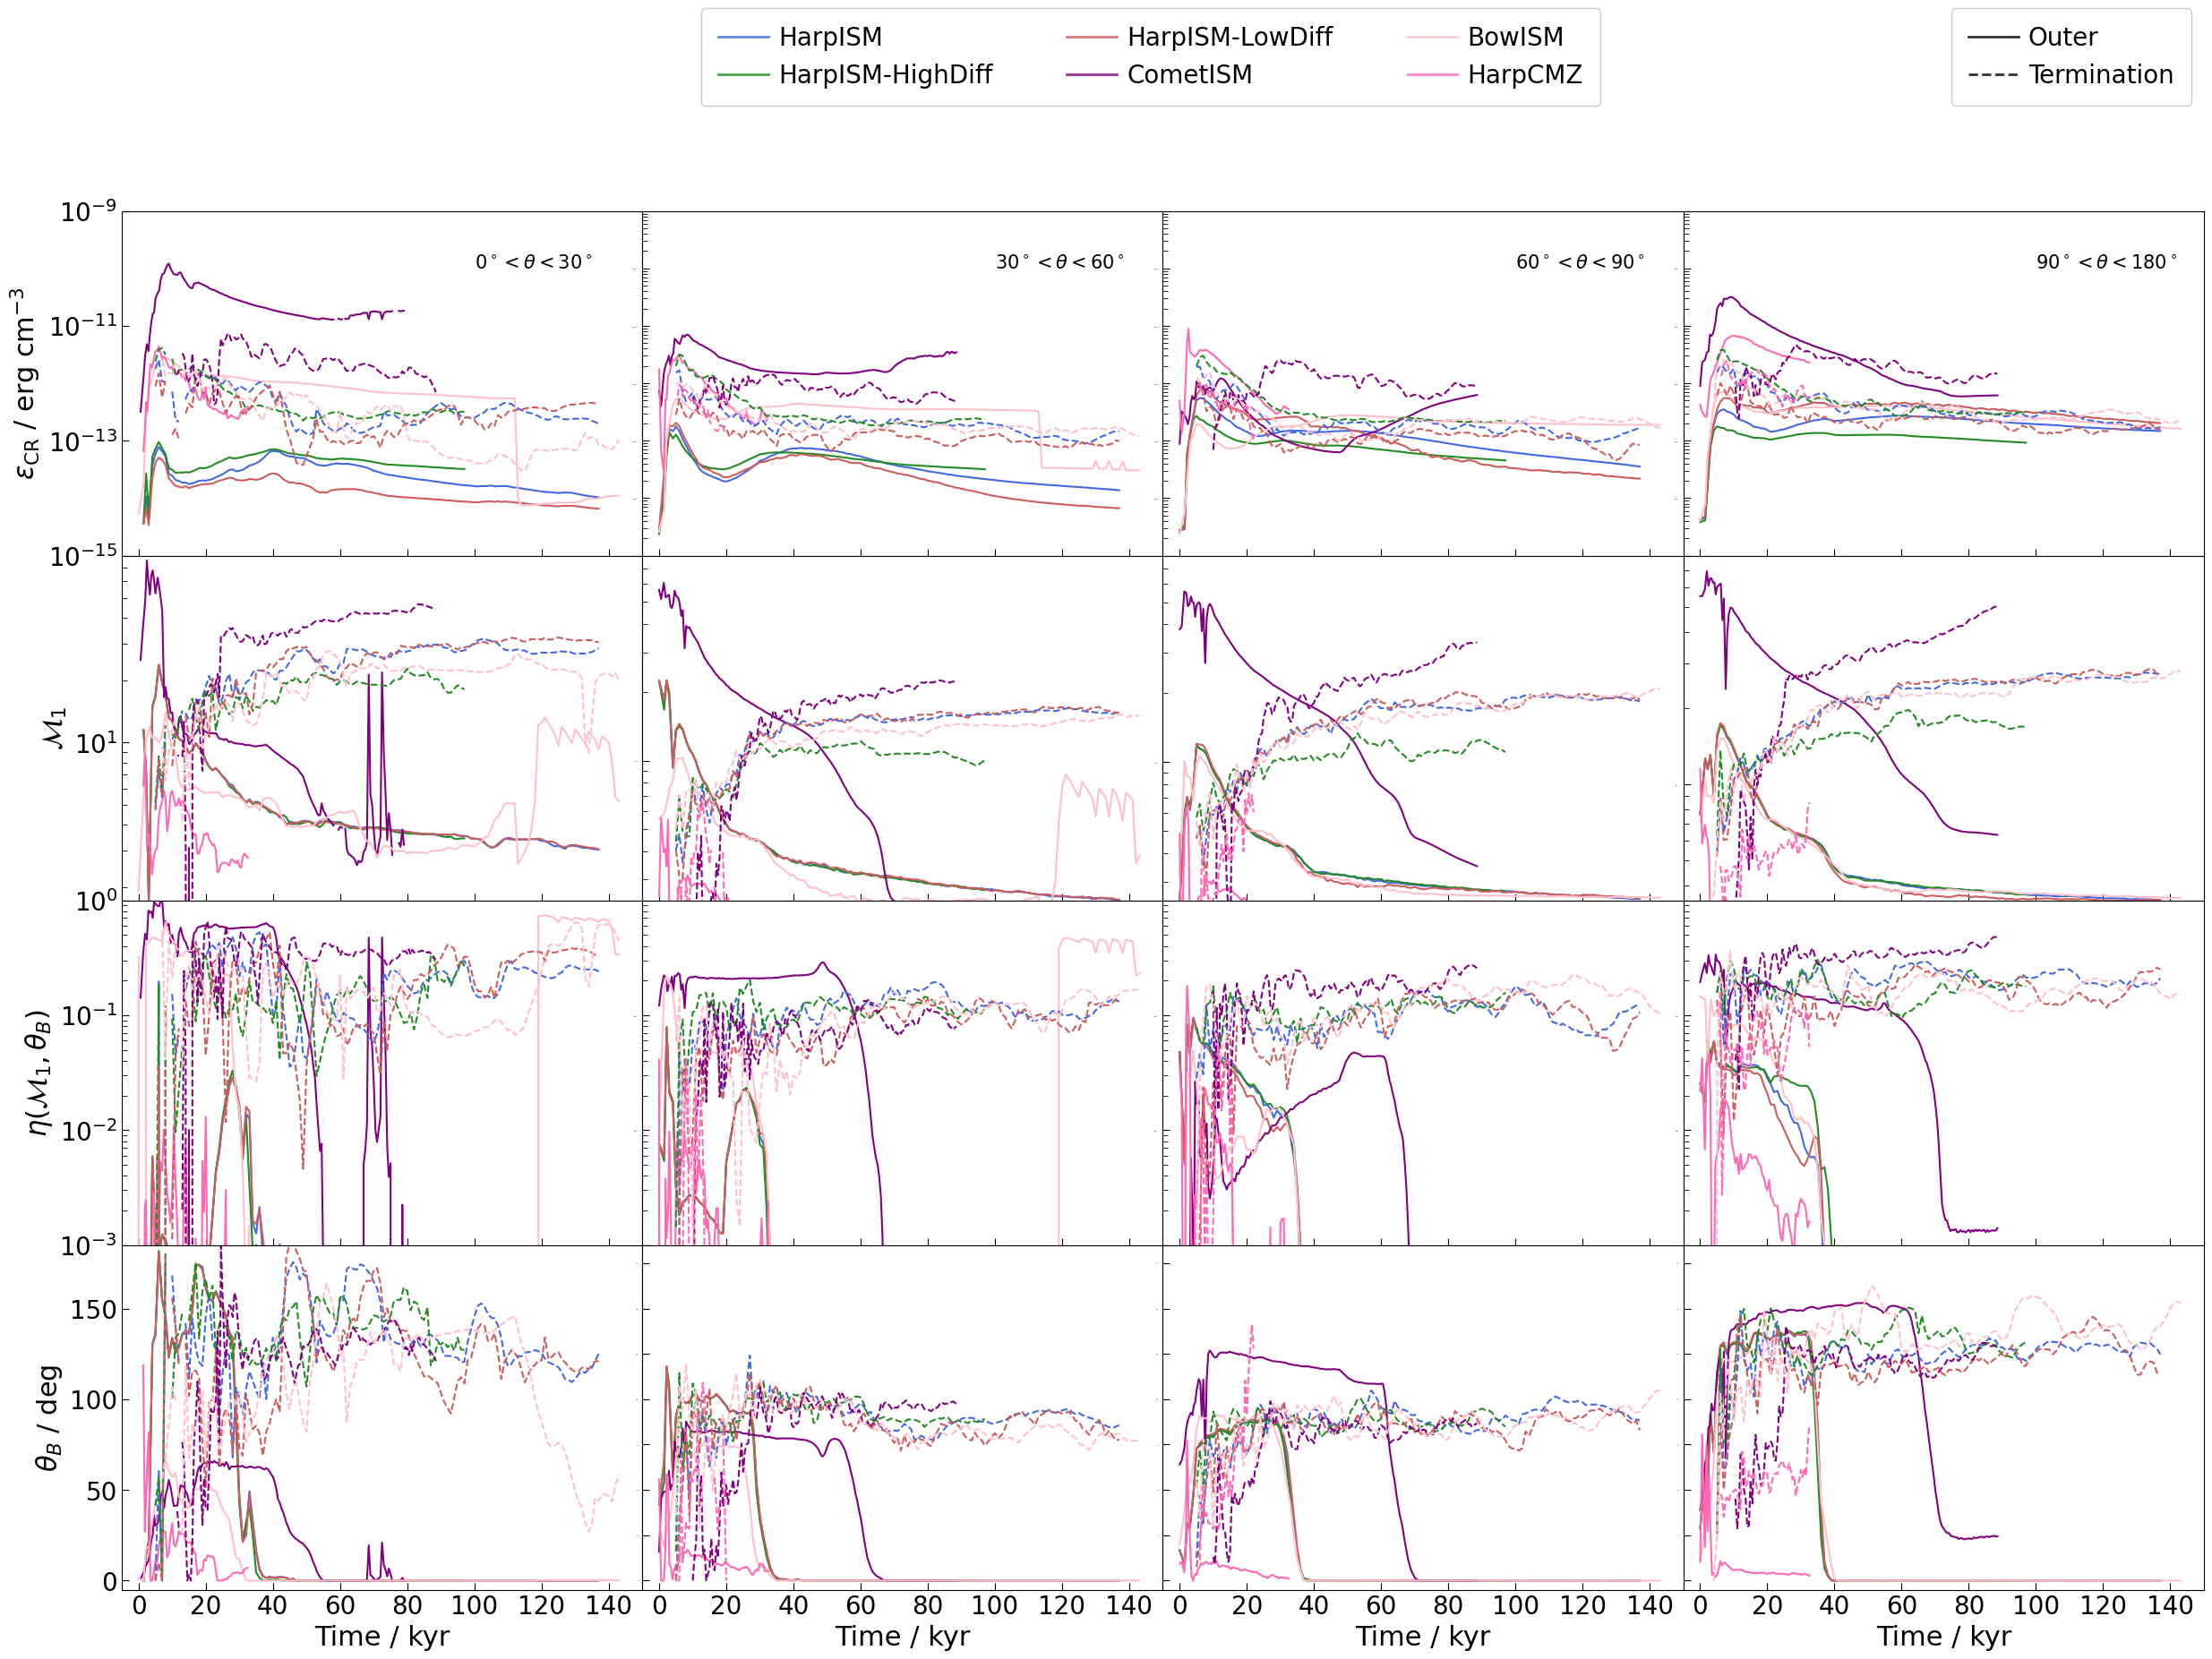

In [6]:
fig = plt.figure(figsize=(30,20))
gs = fig.add_gridspec( len(params), len(theta_ranges), hspace=0, wspace=0)
axs = gs.subplots(sharex=True, sharey=False)


for ish, shock_type in enumerate(shock_types):
    with h5py.File(f"../data/polar_time_series_{shock_type}.h5", "r") as f:
        for ibs, bs_name in enumerate(list(bowshock_config.keys())):
            theta_ranges_sim = [(0, 10), (10,20),(20,30), (30, 45), (45,60), (60,75), (75,90), (90,120), (120,150),(150,180)]
            times = (f[bs_name]["times"][()][:-1] * u.s).to(u.kyr)

            # get minimum and maximum value in each range so that we can search index 
            # corresponding to where min and max values are 
            theta_minvals = [theta_ranges_sim[ith][0] for ith in range(len(theta_ranges_sim))]
            theta_maxvals = [theta_ranges_sim[ith][1] for ith in range(len(theta_ranges_sim))]
            print(theta_minvals, theta_maxvals)

            for j, theta_range in enumerate(theta_ranges):

                # find indices where the theta centers cover
                theta_lidx = np.digitize(theta_range[0], theta_minvals, right=True)
                theta_uidx = np.digitize(theta_range[1], theta_maxvals, right=True)

                for i, p in enumerate(params):
                    param_arr = np.sum(f[bs_name][p][()][:,theta_lidx:theta_uidx+1], axis=1)
                    axs[i,j].plot(times, param_arr, ls=shock_type_ls[ish], color=bs_colors[ibs])


                    # labels
                    axs[i,j].set_xlabel("Time / kyr", fontsize=22)
                    if j == 0:
                        axs[i,j].set_ylabel(field_labels[p], fontsize=22)

                    # limits
                    axs[i,j].set_xlim([-5, 150])
                    axs[i,j].set_ylim(field_lims[p])

                    # scales
                    axs[i,j].set_yscale(field_scales[p])

                    # ticks

                    # for x
                    if i == len(params) - 1:
                        axs[i,j].tick_params(axis='x', direction="in", which='major', size=6, labelsize=20)
                        axs[i,j].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=16)
                    else:
                        axs[i,j].tick_params(axis='x', direction="in", which='major', size=6, labelsize=0)
                        axs[i,j].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=0)

                    # for y
                    if j == 0:
                        axs[i,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=20)
                        axs[i,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=16)
                    else:
                        axs[i,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=0)
                        axs[i,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=0)

                    # annotate theta ranges, only for top row (encr)
                    if i == 0:
                        axs[i,j].annotate(rf"${theta_range[0]}^\circ < \theta < {theta_range[1]}^\circ$", xy=(100, 1e-10), fontsize=15, bbox=dict(facecolor='white', edgecolor='none'))


# handles
bs_legend = fig.legend(handles=bs_handles, bbox_to_anchor=(0.68, 1.0), ncols=3, fontsize=20, framealpha=1.0, columnspacing=3.0, borderpad=0.7, borderaxespad=0.5, labelspacing=0.5, handletextpad=0.4)
fig.add_artist(bs_legend)
fig.legend(handles=shck_handles, bbox_to_anchor=(0.9, 1.0), ncols=1, fontsize=20, framealpha=1.0, columnspacing=3.0, borderpad=0.7, borderaxespad=0.5, labelspacing=0.5, handletextpad=0.4)
